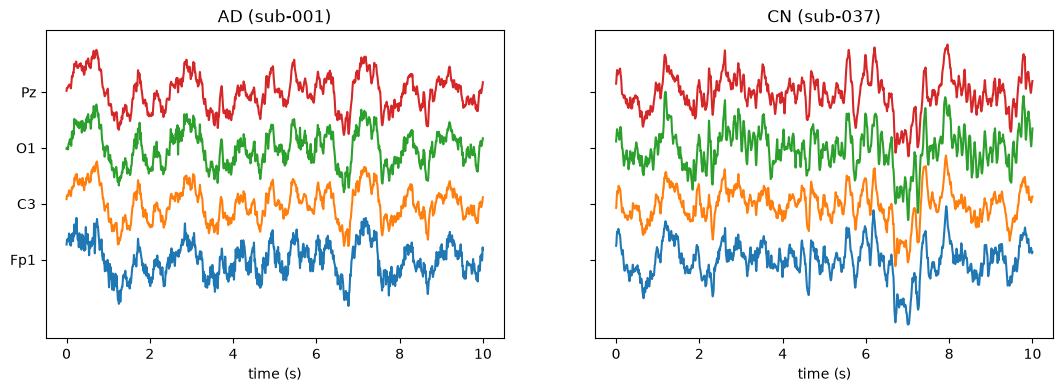

In [1]:
import sys
sys.path.insert(0, "..")          # lets the notebook find our src folder

import numpy as np
import matplotlib.pyplot as plt
from src.data import load_meta, load_raw

meta = load_meta()

# pick the first AD subject and the first CN subject
ad_id = meta[meta.label == "AD"].participant_id.iloc[0]
cn_id = meta[meta.label == "CN"].participant_id.iloc[0]

channels = ["Fp1", "C3", "O1", "Pz"]      # front, centre, back, midline

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

for ax, name, sid in [(axes[0], "AD", ad_id), (axes[1], "CN", cn_id)]:
    raw = load_raw(sid)                                   # load one recording
    fs = raw.info["sfreq"]                                # sampling rate (500 Hz)
    start, stop = int(60 * fs), int(70 * fs)              # seconds 60 to 70, as sample numbers
    data = raw.get_data(picks=channels, start=start, stop=stop) * 1e6   # volts -> microvolts
    time = np.arange(data.shape[1]) / fs                  # sample number -> seconds

    for i in range(len(channels)):
        ax.plot(time, data[i] + i * 100)                  # shift each channel up so they don't overlap

    ax.set_yticks([0, 100, 200, 300])
    ax.set_yticklabels(channels)
    ax.set_title(f"{name} ({sid})")
    ax.set_xlabel("time (s)")

plt.show()

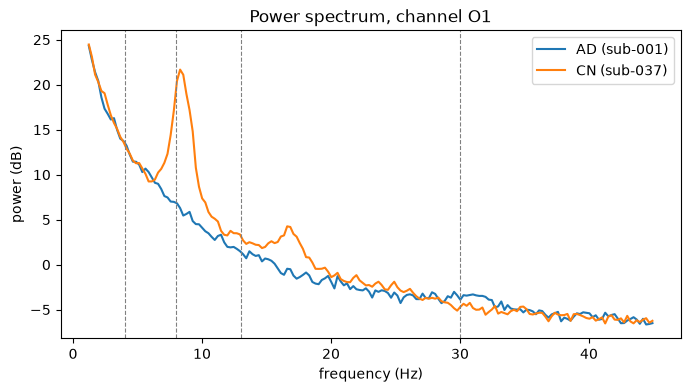

In [2]:
fig, ax = plt.subplots(figsize=(8, 4))

for name, sid in [("AD", ad_id), ("CN", cn_id)]:
    raw = load_raw(sid)

    # power spectrum of channel O1, from 1 to 45 Hz
    spec = raw.compute_psd(fmin=1, fmax=45, picks=["O1"], verbose="ERROR")
    freqs = spec.freqs                       # the frequencies (Hz)
    power = spec.get_data()[0] * 1e12        # volts^2 -> microvolts^2
    ax.plot(freqs, 10 * np.log10(power), label=f"{name} ({sid})")   # log scale (dB)

# mark the band edges: delta | theta | alpha | beta | gamma
for edge in [4, 8, 13, 30]:
    ax.axvline(edge, color="gray", linestyle="--", linewidth=0.8)

ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("power (dB)")
ax.set_title("Power spectrum, channel O1")
ax.legend()
plt.show()

In [3]:
import pandas as pd

# the five bands, in Hz
bands = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 45)}

results = {}
for name, sid in [("AD", ad_id), ("CN", cn_id)]:
    raw = load_raw(sid)

    # power spectrum of channel O1, 1 to 45 Hz
    spec = raw.compute_psd(fmin=1, fmax=45, picks=["O1"], verbose="ERROR")
    freqs = spec.freqs
    power = spec.get_data()[0]
    total = power.sum()                              # total power from 1 to 45 Hz

    fractions = {}
    for band, (low, high) in bands.items():
        in_band = (freqs >= low) & (freqs < high)    # frequencies that fall inside this band
        fractions[band] = power[in_band].sum() / total   # share of the total
    fractions["theta/alpha"] = fractions["theta"] / fractions["alpha"]

    results[name] = fractions

print(pd.DataFrame(results).round(3))

                AD     CN
delta        0.786  0.539
theta        0.124  0.125
alpha        0.040  0.295
beta         0.035  0.033
gamma        0.014  0.008
theta/alpha  3.091  0.424
